# Pipeline de dados — Olist

## Integrantes
Natan Hideaki Higuti

Breno Kenedy Sato Jacobi

Victor Hugo Allebrandt Freitag

Renato Augusto Sche

Kaique venandi Moreira 

## Pergunta de negócio

Quais categorias têm o maior valor de produtos vendidos em
pedidos entregues, por mês?

- Valor dos produtos: soma de price, sem frete.
- Mês de referência: mês da compra, em order_purchase_timestamp.
- Escopo: pedidos com order_status igual a delivered.
- Cada linha da Gold representará uma categoria em um mês.
- Métricas previstas: valor dos produtos e quantidade de
  pedidos distintos.
  

## Dataset escolhido
Olist — dados de comércio eletrônico brasileiro.

## Segundo candidato
Chinook — loja de músicas.

## Justificativa inicial
Escolhemos o Olist por permitir trabalhar com pedidos, itens e produtos,
praticando junções, tratamento de dados e análises de vendas.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from contextlib import closing
from copy import deepcopy
from decimal import Decimal
import csv
import io
import json
import logging
import time
import sys
import sqlite3
import hashlib
import requests
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

# Os caminhos partem da pasta do notebook. O fim do periodo e exclusivo.
CONFIG = {
    'data': Path('data'), 'bronze': Path('data/bronze'),
    'silver': Path('data/silver'), 'gold': Path('data/gold'),
    'historico': Path('historico_execucoes.csv'), 'log': Path('pipeline.log'),
    'timeout': 60, 'status': 'delivered', 'inicio': None, 'fim': None,
    'categoria_ausente': 'sem_categoria', 'fracao_inicial': 0.8,
    'testes': Path('validacao'), 'amostras': Path('amostras'),
    'url_base': 'https://huggingface.co/datasets/bulutttt/olist-raw-data/resolve/main',
    'url_chinook': 'https://raw.githubusercontent.com/lerocha/chinook-database/master/ChinookDatabase/DataSources/Chinook_Sqlite.sqlite',
    'arquivos': {'silver': 'itens_pedidos.parquet', 'categoria': 'vendas_categoria_mes.parquet',
                 'mensal': 'vendas_mes.parquet', 'banco': 'olist.sqlite'},
    'fontes': {
        'pedidos': {'arquivo': 'olist_orders_dataset.csv', 'colunas': ['order_id','order_status','order_purchase_timestamp'], 'chave': ['order_id']},
        'itens': {'arquivo': 'olist_order_items_dataset.csv', 'colunas': ['order_id','order_item_id','product_id','price'], 'chave': ['order_id','order_item_id']},
        'produtos': {'arquivo': 'olist_products_dataset.csv', 'colunas': ['product_id','product_category_name'], 'chave': ['product_id']},
    },
}
logger = logging.getLogger('pipeline_olist')
logger.setLevel(logging.INFO)
logger.propagate = False
for handler in logger.handlers[:]:
    handler.close()
    logger.removeHandler(handler)
handler = logging.FileHandler(CONFIG['log'], encoding='utf-8')
handler.setFormatter(logging.Formatter('%(asctime)s %(levelname)s %(message)s'))
logger.addHandler(handler)

def parametros():
    return json.dumps(CONFIG, default=str, ensure_ascii=False, sort_keys=True)

def executar_etapa(nome, acao):
    # A excecao e mantida para impedir a execucao das proximas etapas.
    inicio = time.perf_counter()
    horario = datetime.now(timezone.utc).isoformat()
    lidas = escritas = 0
    estado, mensagem = 'OK', ''
    logger.info('Inicio %s; parametros=%s', nome, parametros())
    try:
        resultado, lidas, escritas = acao()
        return resultado
    except Exception as erro:
        estado, mensagem = 'ERROR', str(erro)
        logger.exception('Falha em %s', nome)
        raise
    finally:
        duracao = time.perf_counter()-inicio
        caminho = CONFIG['historico']
        caminho.parent.mkdir(parents=True, exist_ok=True)
        novo = not caminho.exists()
        with caminho.open('a', newline='', encoding='utf-8') as arquivo:
            escritor = csv.DictWriter(arquivo, fieldnames=['etapa','horario','duracao_segundos','linhas_lidas','linhas_escritas','estado','mensagem','parametros'])
            if novo:
                escritor.writeheader()
            escritor.writerow(dict(etapa=nome, horario=horario, duracao_segundos=duracao,
                linhas_lidas=lidas, linhas_escritas=escritas, estado=estado, mensagem=mensagem, parametros=parametros()))
        logger.info('Fim %s; estado=%s; segundos=%.3f; lidas=%s; escritas=%s', nome, estado, duracao, lidas, escritas)

def origem_fonte(nome):
    fonte = CONFIG['fontes'][nome]
    return fonte.get('origem', f"{CONFIG['url_base']}/{fonte['arquivo']}")

def ler_fonte(nome, selecionar=True):
    origem = origem_fonte(nome)
    if str(origem).startswith(('https://','http://')):
        resposta = requests.get(origem, timeout=CONFIG['timeout'])
        resposta.raise_for_status()
        entrada = io.BytesIO(resposta.content)
    else:
        entrada = Path(origem)
    # Na Bronze, vazios permanecem como texto vazio e nao viram outro valor.
    return pd.read_csv(entrada, usecols=CONFIG['fontes'][nome]['colunas'] if selecionar else None,
                       dtype=str, keep_default_na=False)

print('Python utilizado:', sys.executable)
print('Versao do pandas:', pd.__version__)

Python utilizado: c:\Users\foxyg\Documents\GitHub\pipeline-olist\.venv\Scripts\python.exe
Versao do pandas: 3.1.0


In [3]:
# Leitura exploratoria completa, ainda fora das camadas do pipeline.
# O pandas reconhece tipos e ausencias para este diagnostico.
def explorar(nome):
    texto = ler_fonte(nome, selecionar=False).to_csv(index=False)
    return pd.read_csv(io.StringIO(texto))

pedidos = explorar('pedidos')
itens = explorar('itens')
produtos = explorar('produtos')

In [4]:
# Reune as tabelas para repetir a mesma verificacao em cada fonte.
fontes = {
    "pedidos": pedidos,
    "itens": itens,
    "produtos": produtos,
}

for nome, tabela in fontes.items():
    # shape retorna a quantidade de linhas e colunas do DataFrame.
    linhas, colunas = tabela.shape
    print(f"{nome}: {linhas:,} linhas e {colunas} colunas")

pedidos: 99,441 linhas e 8 colunas
itens: 112,650 linhas e 7 colunas
produtos: 32,951 linhas e 9 colunas


In [5]:
# Exibe cinco linhas de cada fonte para reconhecer sua estrutura.
# Esta amostra inicial nao comprova a qualidade de toda a base.
for nome, tabela in fontes.items():
    print(f"\nFonte: {nome}")
    display(tabela.head())


Fonte: pedidos


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



Fonte: itens


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



Fonte: produtos


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


## Avaliação do segundo candidato — Chinook

Vamos examinar as tabelas Invoice (vendas) e InvoiceLine
(itens das vendas) para comparar este dataset com o Olist.

In [6]:
from pathlib import Path
import requests
import sqlite3

# Pasta de avaliação dos candidatos, ainda fora das camadas do pipeline.
pasta_amostras = CONFIG["amostras"]
pasta_amostras.mkdir(exist_ok=True)

caminho_chinook = pasta_amostras / "chinook.sqlite"

url_chinook = CONFIG["url_chinook"]

# timeout limita a espera da requisicao; raise_for_status sinaliza erros HTTP.
resposta = requests.get(url_chinook, timeout=CONFIG["timeout"])
resposta.raise_for_status()

# Salva o banco recebido no caminho relativo amostras/chinook.sqlite.
caminho_chinook.write_bytes(resposta.content)

# Consulta cinco linhas por tabela; LIMIT 5 nao mede o total de registros.
# closing fecha a conexao depois das consultas da avaliacao.
with closing(sqlite3.connect(caminho_chinook)) as conexao:
    vendas_chinook = pd.read_sql_query(
        'SELECT * FROM "Invoice" LIMIT 5',
        conexao,
    )

    itens_chinook = pd.read_sql_query(
        'SELECT * FROM "InvoiceLine" LIMIT 5',
        conexao,
    )

print("Amostra de vendas:")
display(vendas_chinook)

print("Amostra de itens das vendas:")
display(itens_chinook)

Amostra de vendas:


,InvoiceId,CustomerId,InvoiceDate,BillingAddress,BillingCity,BillingState,BillingCountry,BillingPostalCode,Total
0,1,2,2021-01-01 00:00:00,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,1.98
1,2,4,2021-01-02 00:00:00,Ullevålsveien 14,Oslo,NaN,Norway,0171,3.96
2,3,8,2021-01-03 00:00:00,Grétrystraat 63,Brussels,NaN,Belgium,1000,5.94
3,4,14,2021-01-06 00:00:00,8210 111 ST NW,Edmonton,AB,Canada,T6G 2C7,8.91
4,5,23,2021-01-11 00:00:00,69 Salem Street,Boston,MA,USA,2113,13.86


Amostra de itens das vendas:


,InvoiceLineId,InvoiceId,TrackId,UnitPrice,Quantity
0,1,1,2,0.99,1
1,2,1,4,0.99,1
2,3,2,6,0.99,1
3,4,2,8,0.99,1
4,5,2,10,0.99,1


## Bloco 1 — Escolha do dataset

### Comparação dos candidatos

Os dois candidatos possuem tabelas relacionadas e colunas de data
que permitem analisar vendas. Ambos foram acessados diretamente,
sem necessidade de cadastro.

No Chinook, examinamos amostras de Invoice e InvoiceLine,
relacionadas por InvoiceId. No Olist, examinamos pedidos, itens
e produtos, relacionados por order_id e product_id.

### P1. Qual dataset escolhemos e por quê?

Escolhemos o Olist porque o contexto de comércio eletrônico
brasileiro está mais alinhado ao interesse do grupo. As fontes
de pedidos, itens e produtos permitem praticar junções e analisar
vendas por categoria e período.

O Chinook também permite analisar vendas, mas preferimos
trabalhar com o contexto e as fontes do Olist.

### P2. Quantas fontes possui e quantas linhas tem a maior?

No recorte escolhido, utilizaremos três arquivos do Olist:

- Pedidos: 99.441 linhas e 8 colunas.
- Itens: 112.650 linhas e 7 colunas.
- Produtos: 32.951 linhas e 9 colunas.

A maior fonte utilizada é a de itens, com 112.650 linhas.
Esses três arquivos são parte do dataset, não sua totalidade.

### P3. Que problema de qualidade observamos na amostra?

Na tabela de produtos, identificamos uma inconsistência na
nomenclatura: product_name_lenght e product_description_lenght
utilizam "lenght" em vez de "length".

Registramos o problema sem alterar os dados nesta etapa.

### Critérios de escolha

- Três fontes que precisam ser combinadas.
- Colunas de data e categoria que permitem agregações.
- Download direto sem cadastro.

## Bloco 2 — Conhecer as fontes e definir a pergunta

Nesta etapa, examinamos as dimensões, os tipos das colunas,
as primeiras linhas e os valores ausentes de cada fonte,
sem modificar os dados originais.

In [7]:
# Diagnostico das fontes: tamanho, tipos reconhecidos e nulos por coluna.
# Este resumo apenas observa os dados; nao faz limpeza ou conversao.
for nome, tabela in fontes.items():
    print(f"\nFonte: {nome}")
    print(f"Linhas: {tabela.shape[0]:,}")
    print(f"Colunas: {tabela.shape[1]}")

    # isna marca ausencias; sum conta essas marcacoes em cada coluna.
    # As contagens nao devem ser somadas para obter linhas afetadas.
    resumo = pd.DataFrame({
        "tipo": tabela.dtypes.astype(str),
        "nulos": tabela.isna().sum(),
    })

    display(resumo)
    display(tabela.head())


Fonte: pedidos
Linhas: 99,441
Colunas: 8


,tipo,nulos
order_id,str,0
customer_id,str,0
order_status,str,0
order_purchase_timestamp,str,0
order_approved_at,str,160
order_delivered_carrier_date,str,1783
order_delivered_customer_date,str,2965
order_estimated_delivery_date,str,0


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



Fonte: itens
Linhas: 112,650
Colunas: 7


,tipo,nulos
order_id,str,0
order_item_id,int64,0
product_id,str,0
seller_id,str,0
shipping_limit_date,str,0
price,float64,0
freight_value,float64,0


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



Fonte: produtos
Linhas: 32,951
Colunas: 9


,tipo,nulos
product_id,str,0
product_category_name,str,610
product_name_lenght,float64,610
product_description_lenght,float64,610
product_photos_qty,float64,610
product_weight_g,float64,2
product_length_cm,float64,2
product_height_cm,float64,2
product_width_cm,float64,2


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [8]:
# Investiga se a ausencia da data de entrega varia conforme o status.
# assign cria uma tabela temporaria, sem modificar o DataFrame pedidos.
resumo_entregas = (
    pedidos
    .assign(
        sem_data_entrega=pedidos["order_delivered_customer_date"].isna()
    )
    .groupby("order_status")
    # size conta linhas; sum conta os valores True de sem_data_entrega.
    .agg(
        total_pedidos=("order_id", "size"),
        sem_data_entrega=("sem_data_entrega", "sum"),
    )
)

display(resumo_entregas)

,total_pedidos,sem_data_entrega
order_status,,
approved,2,2
canceled,625,619
created,5,5
delivered,96478,8
invoiced,314,314
processing,301,301
shipped,1107,1107
unavailable,609,609


### Interpretação dos nulos nas datas de entrega

A ausência de order_delivered_customer_date pode representar
uma etapa ainda não concluída do pedido, em vez de um erro.

Na base examinada, os 1.107 pedidos com status shipped estão
sem data de entrega ao cliente. Esse resultado é compatível
com pedidos enviados cuja entrega ainda não foi registrada.

Porém, também encontramos 8 pedidos com status delivered sem
data de entrega. Esses casos precisam de investigação, pois
há uma inconsistência entre o status e o preenchimento da data.

Entre os 625 pedidos cancelados, 619 não possuem data de
entrega e 6 possuem. Não podemos determinar a causa apenas
com essa contagem.

Nenhum registro foi corrigido ou removido nesta etapa.

### Relacionamentos entre as fontes

- itens.order_id se relaciona com pedidos.order_id.
- itens.product_id se relaciona com produtos.product_id.
- A data de referência será order_purchase_timestamp.

A combinação order_id + order_item_id é a chave candidata
de cada item. Sua unicidade ainda será verificada.
Também verificaremos a unicidade das chaves de pedidos e
produtos antes das junções.

### Fluxo previsto das camadas

Fonte → Bronze:
- Pedidos: order_id, order_status e order_purchase_timestamp.
- Itens: order_id, order_item_id, product_id e price.
- Produtos: product_id e product_category_name.
- Preservar os valores e acrescentar metadados de extração.

Bronze → Silver:
- Padronizar tipos e investigar duplicidades e nulos.
- Combinar itens, pedidos e produtos.
- Validar as junções e aplicar o escopo de pedidos entregues.
- Cada linha representará um item de um pedido.

Silver → Gold:
- Agregar por mês da compra e categoria.
- Calcular a soma de price e a quantidade de pedidos distintos.

### P1. Que tabela agregada responde à pergunta?
### Nessa tabela, uma linha representa o quê?

Uma tabela com mês da compra, categoria, valor dos produtos
vendidos e quantidade de pedidos distintos.

Cada linha representará uma categoria em um mês.
O valor será a soma de price, sem frete, considerando pedidos
com status delivered. Os pedidos serão contados por order_id
distinto, e não pela quantidade de linhas de itens.

Um pedido pode conter várias categorias. Portanto, as contagens
de pedidos por categoria não podem ser somadas para obter
o total geral de pedidos.

### P2. Quais fontes ou colunas não são necessárias?
### Por que deixá-las de fora é uma decisão de Extract?

Para esta pergunta, não precisamos identificar clientes,
vendedores, frete, dimensões físicas dos produtos nem suas
descrições. Também não precisamos das outras datas do pedido,
pois o mês será definido pela data da compra.

Outras fontes, como pagamentos e avaliações, não são necessárias
porque analisaremos o valor dos produtos em price, sem avaliar
pagamentos ou satisfação.

Selecionar as colunas na extração reduz o volume armazenado e
mantém as entradas alinhadas à pergunta. Essa seleção não
corrige os valores originais.

As datas de entrega foram úteis para a exploração dos nulos,
mas não são necessárias para a agregação escolhida.

### P3. Algum nulo encontrado pode carregar informação
### em vez de indicar erro?

Sim. A ausência da data de entrega pode indicar que a entrega
ainda não foi registrada, dependendo do status do pedido.

Os 1.107 pedidos com status shipped não possuem data de entrega
ao cliente. Entretanto, há também 8 pedidos delivered sem essa
data, que exigem investigação. Portanto, não interpretaremos
todos os nulos dessa coluna da mesma maneira.

## Bloco 3 — Extract: construir a Bronze

A Bronze armazenará as colunas selecionadas das fontes,
preservando seus valores e acrescentando a origem e o
horário da extração.

Nesta etapa não faremos limpeza, junções nem filtro de status.

In [9]:
# Caminhos relativos definidos na configuracao do inicio.
destino_bronze = CONFIG['bronze']
destino_silver = CONFIG['silver']
destino_gold = CONFIG['gold']
for pasta in [destino_bronze,destino_silver,destino_gold]:
    pasta.mkdir(parents=True,exist_ok=True)
    print(f'{pasta}: existe = {pasta.is_dir()}')

data\bronze: existe = True
data\silver: existe = True
data\gold: existe = True


In [10]:
def extract(destino_bronze):
    """Extrai a carga completa; para incremental usamos extract_lote()."""
    def acao():
        pasta = Path(destino_bronze)
        pasta.mkdir(parents=True, exist_ok=True)
        if (pasta/'manifesto.json').exists():
            raise ValueError('Bronze incremental: use pipeline_incremental para preservar os lotes.')
        horario = datetime.now(timezone.utc).isoformat()
        resumo = []
        for nome, fonte in CONFIG['fontes'].items():
            try:
                tabela = ler_fonte(nome)
                linhas, colunas = tabela.shape
                tabela['_extraido_em'] = horario
                tabela['_origem'] = str(origem_fonte(nome))
                tabela.to_parquet(pasta/f'{nome}.parquet', index=False)
            except Exception as erro:
                raise RuntimeError(f'Falha na extracao de {nome}: {origem_fonte(nome)}') from erro
            resumo.append(dict(fonte=nome, linhas_lidas=linhas, linhas_gravadas=linhas,
                               colunas_fonte=colunas, colunas_bronze=colunas+2))
        resultado = pd.DataFrame(resumo)
        return resultado, int(resultado.linhas_lidas.sum()), int(resultado.linhas_gravadas.sum())
    return executar_etapa('extract', acao)

In [11]:
# Executa a extracao e mostra o resumo retornado pela funcao.
# Requer executar antes as celulas de imports, URL_BASE e caminhos.
resumo_extracao = extract(destino_bronze)
display(resumo_extracao)

,fonte,linhas_lidas,linhas_gravadas,colunas_fonte,colunas_bronze
0,pedidos,99441,99441,3,5
1,itens,112650,112650,4,6
2,produtos,32951,32951,2,4


In [12]:
def contagens_bronze(pasta):
    """Le os Parquets gravados e retorna a quantidade de linhas por fonte."""
    return {
        nome: len(pd.read_parquet(pasta / f"{nome}.parquet"))
        for nome in ["pedidos", "itens", "produtos"]
    }

# Registra o estado em disco antes de executar novamente a extracao.
antes = contagens_bronze(destino_bronze)

extract(destino_bronze)

# Reabre os arquivos para verificar o resultado realmente persistido.
depois = contagens_bronze(destino_bronze)

comparacao = pd.DataFrame({
    "antes": antes,
    "depois": depois,
})

comparacao["mesma_contagem"] = (
    comparacao["antes"] == comparacao["depois"]
)

display(comparacao)

# Verifica contagens, nao igualdade de valores ou metadados.
# Se houver diferenca, assert interrompe esta celula com a mensagem abaixo.
assert antes == depois, "As contagens da Bronze mudaram."

,antes,depois,mesma_contagem
pedidos,99441,99441,True
itens,112650,112650,True
produtos,32951,32951,True


### Bloco 3 — Perguntas de verificação

#### P1. Quantas linhas e colunas tem cada arquivo da Bronze?
#### Os números batem com os da fonte original?

- Pedidos: 99.441 linhas e 5 colunas.
- Itens: 112.650 linhas e 6 colunas.
- Produtos: 32.951 linhas e 4 colunas.

As contagens de linhas coincidem com as fontes examinadas.

A Bronze contém somente as colunas selecionadas para a análise,
acrescentadas de _origem e _extraido_em. Por isso, não possui
todas as colunas dos arquivos originais.

#### P2. O que aconteceu com o número de linhas na segunda execução?

As contagens permaneceram iguais:

- Pedidos: 99.441 → 99.441.
- Itens: 112.650 → 112.650.
- Produtos: 32.951 → 32.951.

A extração substitui os mesmos arquivos Parquet em vez de
acrescentar linhas aos arquivos anteriores.

O teste confirmou estabilidade das contagens, mas não comparou
todos os valores. O horário da extração pode mudar.

#### P3. Por que a Bronze não deve receber correções?

Porque ela preserva os valores das colunas selecionadas da fonte,
permitindo rastrear sua origem e refazer as transformações quando
as regras mudarem.

Limpeza, conversão de tipos e tratamento de campos ausentes
serão realizados na Silver.

#### P4. Se a fonte sair do ar amanhã, o que continua funcionando?

Os arquivos já gravados na Bronze continuam disponíveis para
consulta e para alimentar as futuras etapas de transformação
e carga, desde que essas etapas leiam as camadas locais.

Uma nova extração dependerá da disponibilidade da fonte.
Neste momento, transform() e load() ainda não foram implementadas.

### Conferência dos blocos iniciais

Mantivemos as perguntas, a comparação dos candidatos e as decisões iniciais.
Acrescentamos configuração central e fechamento explícito da conexão do Chinook.
O grupo possui cinco integrantes, com autorização do professor confirmada pelo grupo.
O roteiro prevê três ou quatro, e essa exceção já foi autorizada.

Além das contagens, vamos comparar os valores das colunas selecionadas na Bronze.
O horário de extração pode mudar entre execuções.

In [13]:
for nome, fonte in CONFIG['fontes'].items():
    original = ler_fonte(nome)
    bronze = pd.read_parquet(CONFIG['bronze']/f'{nome}.parquet')
    pd.testing.assert_frame_equal(original[fonte['colunas']], bronze[fonte['colunas']])
    assert bronze['_origem'].eq(str(origem_fonte(nome))).all()
    assert pd.to_datetime(bronze['_extraido_em'], utc=True, errors='coerce').notna().all()
print('Bronze conferida: valores, colunas selecionadas e metadados.')

Bronze conferida: valores, colunas selecionadas e metadados.


## Bloco 4 — Transform: construir a Silver

Cada linha da Silver representa um item de um pedido.
Decidimos usar `order_id + order_item_id` porque o número do item se repete
entre pedidos diferentes. Validamos a unicidade antes de fazer as junções.

Decidimos remover cópias idênticas dentro do mesmo lote porque representam
repetição do mesmo registro. Se uma chave tiver valores diferentes no mesmo lote,
interrompemos a etapa para investigar. Entre lotes, a versão posterior substitui
a anterior; essa é a política de correção da carga incremental.

Decidimos preencher categoria ausente com `sem_categoria` porque remover o item
esconderia seu valor na análise. Chaves, status e datas de compra ausentes
interrompem a transformação; não inventamos esses valores.

Decidimos usar centavos inteiros porque o preço possui duas casas decimais.
Isso permite conferir as somas com igualdade exata. Preços negativos, vazios
ou malformados interrompem a etapa. As datas e os identificadores de item
são convertidos para seus tipos adequados. Os nomes selecionados já estão em snake_case.

As demais colunas com nulos ficaram fora da Bronze conforme a justificativa do bloco 2.
O filtro de pedidos entregues é aplicado depois da conferência das junções.

In [14]:
def ler_bronze(pasta, nome, auditoria):
    pasta = Path(pasta)
    manifesto = pasta/'manifesto.json'
    arquivos = ([pasta/lote/f'{nome}.parquet' for lote in json.loads(manifesto.read_text(encoding='utf-8'))]
                if manifesto.exists() else [pasta/f'{nome}.parquet'])
    partes = []
    fonte = CONFIG['fontes'][nome]
    for ordem, arquivo in enumerate(arquivos):
        if not arquivo.is_file():
            raise FileNotFoundError(f'Transform precisa do Extract: falta {arquivo}')
        tabela = pd.read_parquet(arquivo)[fonte['colunas']].copy()
        auditoria.append(dict(regra=f'{nome}: linhas lidas lote {ordem}', afetados=len(tabela)))
        antes = len(tabela)
        tabela = tabela.drop_duplicates()
        auditoria.append(dict(regra=f'{nome}: copias identicas lote {ordem}', afetados=antes-len(tabela)))
        if tabela[fonte['chave']].isna().any().any() or tabela[fonte['chave']].eq('').any().any():
            raise ValueError(f'Chave ausente em {nome}')
        if tabela.duplicated(fonte['chave']).any():
            raise ValueError(f'Chave com valores conflitantes no mesmo lote: {nome}')
        partes.append(tabela)
    combinado = pd.concat(partes, ignore_index=True)
    antes = len(combinado)
    combinado = combinado.drop_duplicates(fonte['chave'], keep='last')
    auditoria.append(dict(regra=f'{nome}: versoes anteriores substituidas', afetados=antes-len(combinado)))
    return combinado

def transform(origem_bronze, destino_silver):
    def acao():
        auditoria = []
        pedidos = ler_bronze(origem_bronze, 'pedidos', auditoria)
        itens = ler_bronze(origem_bronze, 'itens', auditoria)
        produtos = ler_bronze(origem_bronze, 'produtos', auditoria)
        lidas = sum(r['afetados'] for r in auditoria if ': linhas lidas' in r['regra'])
        # Os nomes selecionados ja seguem snake_case. Preservamos os identificadores.
        itens['order_item_id'] = pd.to_numeric(itens['order_item_id'], errors='raise')
        if not (itens.order_item_id.gt(0).all() and itens.order_item_id.mod(1).eq(0).all()):
            raise ValueError('Numero de item invalido.')
        itens['order_item_id'] = itens.order_item_id.astype('int64')
        assert not itens.duplicated(['order_id','order_item_id']).any()
        valido = itens.price.str.fullmatch(r'[0-9]+(?:\.[0-9]{1,2})?').fillna(False)
        auditoria.append(dict(regra='itens: precos invalidos', afetados=int((~valido).sum())))
        if not valido.all():
            raise ValueError('Preco vazio, negativo ou fora do formato esperado; investigar.')
        itens['valor_centavos'] = itens.price.map(lambda x:int(Decimal(x)*100)).astype('int64')
        itens['price'] = itens.valor_centavos/100
        datas = pd.to_datetime(pedidos.order_purchase_timestamp, errors='coerce')
        auditoria.append(dict(regra='pedidos: datas de compra invalidas', afetados=int(datas.isna().sum())))
        if datas.isna().any():
            raise ValueError('Data de compra ausente ou invalida; investigar.')
        pedidos['order_purchase_timestamp'] = datas
        for quadro, colunas in [(pedidos,['order_status']), (itens,['order_id','product_id'])]:
            if quadro[colunas].isna().any().any() or quadro[colunas].eq('').any().any():
                raise ValueError(f'Campo obrigatorio ausente: {colunas}')
        ausentes = produtos.product_category_name.isna() | produtos.product_category_name.eq('')
        auditoria.append(dict(regra='produtos: categoria preenchida', afetados=int(ausentes.sum())))
        produtos.loc[ausentes,'product_category_name'] = CONFIG['categoria_ausente']
        soma_antes = int(itens.valor_centavos.sum())
        combinado = itens.merge(pedidos, on='order_id', how='left', validate='many_to_one', indicator=True)
        if not combinado['_merge'].eq('both').all():
            raise ValueError('Item sem pedido correspondente.')
        combinado = combinado.drop(columns='_merge').merge(produtos, on='product_id', how='left', validate='many_to_one', indicator=True)
        if not combinado['_merge'].eq('both').all():
            raise ValueError('Item sem produto correspondente.')
        combinado = combinado.drop(columns='_merge')
        soma_depois = int(combinado.valor_centavos.sum())
        assert len(combinado)==len(itens) and soma_antes==soma_depois
        auditoria.append(dict(regra='joins: itens acrescentados ou perdidos', afetados=len(combinado)-len(itens)))
        mascara = combinado.order_status.eq(CONFIG['status'])
        if CONFIG['inicio']:
            mascara &= combinado.order_purchase_timestamp.ge(pd.Timestamp(CONFIG['inicio']))
        if CONFIG['fim']:
            mascara &= combinado.order_purchase_timestamp.lt(pd.Timestamp(CONFIG['fim']))
        auditoria.append(dict(regra='escopo: itens descartados', afetados=int((~mascara).sum())))
        silver = combinado.loc[mascara].copy()
        silver['data_compra'] = silver.order_purchase_timestamp.dt.normalize()
        silver['mes'] = silver.data_compra.dt.strftime('%Y-%m')
        silver = silver.sort_values(['order_id','order_item_id']).reset_index(drop=True)
        pasta = Path(destino_silver)
        pasta.mkdir(parents=True, exist_ok=True)
        silver.to_parquet(pasta/CONFIG['arquivos']['silver'], index=False)
        pd.DataFrame(auditoria).to_csv(pasta/'auditoria.csv', index=False)
        (pasta/'resumo.json').write_text(json.dumps(dict(linhas_bronze=lidas, itens_antes_escopo=len(combinado),
            linhas_silver=len(silver), soma_antes_join=soma_antes, soma_depois_join=soma_depois,
            soma_silver=int(silver.valor_centavos.sum())), indent=2), encoding='utf-8')
        return silver, lidas, len(silver)
    return executar_etapa('transform', acao)

silver = transform(CONFIG['bronze'], CONFIG['silver'])
display(pd.read_csv(CONFIG['silver']/'auditoria.csv'))
display(silver.head())

,regra,afetados
0,pedidos: linhas lidas lote 0,99441
1,pedidos: copias identicas lote 0,0
2,pedidos: versoes anteriores substituidas,0
3,itens: linhas lidas lote 0,112650
4,itens: copias identicas lote 0,0
5,itens: versoes anteriores substituidas,0
6,produtos: linhas lidas lote 0,32951
7,produtos: copias identicas lote 0,0
8,produtos: versoes anteriores substituidas,0
9,itens: precos invalidos,0


,order_id,order_item_id,product_id,price,valor_centavos,order_status,order_purchase_timestamp,product_category_name,data_compra,mes
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,58.90,5890,delivered,2017-09-13 08:59:02,cool_stuff,2017-09-13,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,239.90,23990,delivered,2017-04-26 10:53:06,pet_shop,2017-04-26,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,199.00,19900,delivered,2018-01-14 14:33:31,moveis_decoracao,2018-01-14,2018-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,12.99,1299,delivered,2018-08-08 10:00:35,perfumaria,2018-08-08,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,199.90,19990,delivered,2017-02-04 13:57:51,ferramentas_jardim,2017-02-04,2017-02


### Bloco 4 — Perguntas de verificação

**P1. Quantas linhas tem cada camada e por quê?** A Bronze soma 245,042
linhas nas três fontes. Não comparamos essa soma diretamente com a Silver:
pedidos e produtos enriquecem os itens. Partimos de 112,650
itens e chegamos a 110,197, com 2,453 itens fora do escopo.
A auditoria acima mostra o efeito de cada regra, incluindo duplicidades.

**P2. A soma bateu antes e depois do join?** Sim: 13,591,643.70
reais antes e depois. O código confere a cardinalidade, as linhas e a soma em centavos.

**P3. Qual decisão mais alterou o resultado?** Na carga completa, o filtro de escopo
retirou 2,453 itens e 370,145.59
reais. O preenchimento de categoria muda a classificação, mas não remove valores.

**P4. Algum nulo foi mantido de propósito?** A informação de categoria desconhecida
foi preservada como `sem_categoria`, sem excluir os itens. As datas de entrega
com nulos foram analisadas no bloco 2 e não fazem parte do recorte da Bronze.

**P5. Se a regra mudar, o que reprocessar?** Silver e Gold. A Bronze permanece
preservada, pois guarda os valores anteriores às decisões de transformação.


## Bloco 5 — Load: construir a Gold

A primeira Gold responde à pergunta do início: quais categorias têm o maior
valor de produtos vendidos em pedidos entregues, por mês?

Cada linha representa uma categoria em um mês. Calculamos o valor dos produtos,
sem frete, e os pedidos distintos. Gravamos a agregação em Parquet e SQLite,
substituindo o resultado anterior para não acumular linhas.

## Bloco 6 — Load: modelagem dimensional

Cada linha da fato representa um item de um pedido entregue.
Criamos dim_tempo com data, ano, mês, trimestre e dia da semana, e dim_produto
com o produto e sua categoria. Cada dimensão possui uma chave substituta própria.

A fato guarda as chaves das dimensões, o valor em centavos e os identificadores
do grão. `order_id` e `order_item_id` são dimensões degeneradas: identificam
o item, sem repetir textos descritivos como categoria ou status.

Decidimos reconstruir fato e dimensões juntas. As chaves podem mudar quando
entra um produto anterior na ordenação, mas não misturamos versões do modelo.
No SQLite, a reconstrução do modelo ocorre na mesma transação com PKs e FKs
criadas explicitamente em SQL. As duas Golds e os gráficos do bloco 9 também
ficam no load para que a reconstrução seja completa.

In [15]:
def validar_banco(conexao):
    assert conexao.execute('PRAGMA foreign_keys').fetchone()[0] == 1
    assert conexao.execute('PRAGMA foreign_key_check').fetchall() == []
    assert conexao.execute('PRAGMA integrity_check').fetchone()[0] == 'ok'
    assert len(conexao.execute('PRAGMA foreign_key_list(fato_vendas)').fetchall()) == 2
    for tabela in ['dim_tempo','dim_produto','fato_vendas']:
        assert any(c[5] for c in conexao.execute(f'PRAGMA table_info({tabela})'))

def load(origem_silver, destino_gold):
    def acao():
        entrada = Path(origem_silver)/CONFIG['arquivos']['silver']
        if not entrada.is_file():
            raise FileNotFoundError(f'Load precisa do Transform: falta {entrada}')
        tabela = pd.read_parquet(entrada)
        gold = (tabela.groupby(['mes','product_category_name'], as_index=False)
                .agg(valor_centavos=('valor_centavos','sum'), pedidos_distintos=('order_id','nunique')))
        gold['valor_produtos'] = gold.valor_centavos/100
        mensal = (tabela.groupby('mes', as_index=False)
                  .agg(valor_centavos=('valor_centavos','sum'), pedidos_distintos=('order_id','nunique')))
        mensal['valor_produtos'] = mensal.valor_centavos/100
        tempo = pd.DataFrame({'data':sorted(tabela.data_compra.unique())})
        tempo['data'] = pd.to_datetime(tempo['data'])
        tempo.insert(0,'tempo_sk',range(1,len(tempo)+1))
        tempo['ano'] = tempo.data.dt.year
        tempo['mes'] = tempo.data.dt.month
        tempo['trimestre'] = tempo.data.dt.quarter
        tempo['dia_semana'] = tempo.data.dt.dayofweek  # segunda=0; domingo=6
        produto = tabela[['product_id','product_category_name']].drop_duplicates().sort_values('product_id').reset_index(drop=True)
        assert produto.product_id.is_unique
        produto.insert(0,'produto_sk',range(1,len(produto)+1))
        fato = tabela.merge(tempo[['data','tempo_sk']],left_on='data_compra',right_on='data',validate='many_to_one')
        fato = fato.merge(produto[['product_id','produto_sk']],on='product_id',validate='many_to_one')
        fato = fato[['order_id','order_item_id','tempo_sk','produto_sk','valor_centavos']]
        assert len(fato)==len(tabela) and not fato.duplicated(['order_id','order_item_id']).any()
        assert int(fato.valor_centavos.sum())==int(tabela.valor_centavos.sum())
        pasta = Path(destino_gold)
        pasta.mkdir(parents=True,exist_ok=True)
        with closing(sqlite3.connect(pasta/CONFIG['arquivos']['banco'])) as conexao:
            conexao.execute('PRAGMA foreign_keys=ON')
            # As Golds agregadas sao substituidas, sem acumular resultados antigos.
            gold.to_sql('vendas_categoria_mes',conexao,if_exists='replace',index=False)
            mensal.to_sql('vendas_mes',conexao,if_exists='replace',index=False)
            conexao.execute('BEGIN')
            try:
                for nome in ['fato_vendas','dim_tempo','dim_produto']:
                    conexao.execute(f'DROP TABLE IF EXISTS {nome}')
                conexao.execute('CREATE TABLE dim_tempo (tempo_sk INTEGER PRIMARY KEY, data TEXT UNIQUE NOT NULL, ano INTEGER NOT NULL, mes INTEGER NOT NULL, trimestre INTEGER NOT NULL, dia_semana INTEGER NOT NULL)')
                conexao.execute('CREATE TABLE dim_produto (produto_sk INTEGER PRIMARY KEY, product_id TEXT UNIQUE NOT NULL, product_category_name TEXT NOT NULL)')
                conexao.execute('CREATE TABLE fato_vendas (order_id TEXT NOT NULL, order_item_id INTEGER NOT NULL, tempo_sk INTEGER NOT NULL REFERENCES dim_tempo(tempo_sk), produto_sk INTEGER NOT NULL REFERENCES dim_produto(produto_sk), valor_centavos INTEGER NOT NULL CHECK(valor_centavos>=0), PRIMARY KEY(order_id,order_item_id))')
                datas_sql = tempo.copy()
                datas_sql['data'] = datas_sql.data.dt.strftime('%Y-%m-%d')
                for nome, quadro in [('dim_tempo',datas_sql),('dim_produto',produto),('fato_vendas',fato)]:
                    registros = list(quadro.itertuples(index=False,name=None))
                    if registros:
                        campos = ','.join('?' for _ in quadro.columns)
                        conexao.executemany(f'INSERT INTO {nome} VALUES ({campos})',registros)
                validar_banco(conexao)
                conexao.commit()
            except Exception:
                conexao.rollback()
                raise
            sql = pd.read_sql_query('SELECT mes, product_category_name, valor_centavos, pedidos_distintos, valor_produtos FROM vendas_categoria_mes ORDER BY mes, product_category_name',conexao)
            pd.testing.assert_frame_equal(gold,sql,check_dtype=False)
            sql_mensal = pd.read_sql_query('SELECT mes, valor_centavos, pedidos_distintos, valor_produtos FROM vendas_mes ORDER BY mes',conexao)
            pd.testing.assert_frame_equal(mensal,sql_mensal,check_dtype=False)
            dimensional = pd.read_sql_query('''SELECT substr(t.data,1,7) AS mes, p.product_category_name,
                SUM(f.valor_centavos) AS valor_centavos, COUNT(DISTINCT f.order_id) AS pedidos_distintos
                FROM fato_vendas f JOIN dim_tempo t ON f.tempo_sk=t.tempo_sk
                JOIN dim_produto p ON f.produto_sk=p.produto_sk
                GROUP BY substr(t.data,1,7), p.product_category_name ORDER BY mes, p.product_category_name''',conexao)
            pd.testing.assert_frame_equal(gold.drop(columns='valor_produtos'),dimensional,check_dtype=False)
        quadros = {CONFIG['arquivos']['categoria']:gold, CONFIG['arquivos']['mensal']:mensal,
                   'dim_tempo.parquet':tempo,'dim_produto.parquet':produto,'fato_vendas.parquet':fato}
        for nome, quadro in quadros.items():
            quadro.to_parquet(pasta/nome,index=False)
        graficos = pasta/'graficos'
        graficos.mkdir(exist_ok=True)
        fig, ax = plt.subplots(figsize=(12,6))
        if not gold.empty:
            ranking = gold.groupby('product_category_name').valor_centavos.sum().nlargest(5).index
            visual = gold[gold.product_category_name.isin(ranking)].pivot(index='mes',columns='product_category_name',values='valor_produtos').reindex(mensal.mes).fillna(0)
            visual.plot(ax=ax,marker='.')
            ax.legend(title='Categoria',fontsize=8)
        else:
            ax.text(0.5,0.5,'Sem dados no escopo',ha='center',transform=ax.transAxes)
        ax.set(title='Valor mensal das cinco categorias de maior valor no período',xlabel='Mês da compra',ylabel='Valor dos produtos (R$)')
        ax.tick_params(axis='x',rotation=45)
        fig.tight_layout()
        fig.savefig(graficos/'categorias_mes.png',dpi=140)
        plt.close(fig)
        fig, eixos = plt.subplots(2,1,figsize=(12,7),sharex=True)
        eixos[0].plot(mensal.mes,mensal.valor_produtos,marker='.')
        eixos[0].set(ylabel='Valor dos produtos (R$)',title='Evolução mensal das vendas em pedidos entregues')
        eixos[1].plot(mensal.mes,mensal.pedidos_distintos,marker='.',color='tab:orange')
        eixos[1].set(ylabel='Pedidos distintos',xlabel='Mês da compra')
        eixos[1].tick_params(axis='x',rotation=45)
        fig.tight_layout()
        fig.savefig(graficos/'evolucao_mensal.png',dpi=140)
        plt.close(fig)
        return {'categoria':gold,'mensal':mensal},len(tabela),sum(map(len,quadros.values()))
    return executar_etapa('load',acao)

golds = load(CONFIG['silver'],CONFIG['gold'])
# Mostra os lideres de cada mes; o ranking completo fica na Gold.
lideres = golds['categoria'].sort_values(['mes','valor_centavos','product_category_name'],ascending=[True,False,True]).groupby('mes').head(5)
display(lideres)
display(golds['mensal'])

C:\Users\foxyg\AppData\Local\Temp\ipykernel_6468\3925793808.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  tempo['dia_semana'] = tempo.data.dt.dayofweek  # segunda=0; domingo=6


,mes,product_category_name,valor_centavos,pedidos_distintos,valor_produtos
0,2016-09,beleza_saude,13497,1,134.97
22,2016-10,moveis_decoracao,569052,49,5690.52
24,2016-10,perfumaria,482910,26,4829.10
6,2016-10,brinquedos,410650,22,4106.50
9,2016-10,consoles_games,361936,7,3619.36
...,...,...,...,...,...
1218,2018-08,beleza_saude,11939101,765,119391.01
1267,2018-08,relogios_presentes,6976706,387,69767.06
1220,2018-08,cama_mesa_banho,6089109,555,60891.09
1272,2018-08,utilidades_domesticas,5876336,549,58763.36


,mes,valor_centavos,pedidos_distintos,valor_produtos
0,2016-09,13497,1,134.97
1,2016-10,4032511,265,40325.11
2,2016-12,1090,1,10.90
3,2017-01,11179836,750,111798.36
4,2017-02,23422340,1653,234223.40
5,2017-03,35919885,2546,359198.85
6,2017-04,34066968,2303,340669.68
7,2017-05,48933825,3546,489338.25
8,2017-06,42192337,3135,421923.37
9,2017-07,48160452,3872,481604.52


### Bloco 5 — Perguntas de verificação

**P1. Qual é a resposta?** A tabela de líderes acima mostra as cinco categorias
com maior valor em cada mês. A Gold completa mantém todas as categorias.

**P2. O que se perde na agregação?** A Silver possui 110,197 itens e a primeira
Gold possui 1,273 linhas. Perdemos o detalhe de produto e item,
aceitável para a pergunta por categoria e mês. O detalhe permanece na Silver.

**P3. SQL e pandas são iguais?** As comparações em código passaram para as duas Golds.

**P4. Por que dois formatos?** Parquet facilita leituras analíticas em Python;
SQLite permite consultas SQL. Em Parquet, a Silver ocupa 6,278,045 bytes
e a primeira Gold ocupa 25,067 bytes.

**P5. O que aconteceria com append?** A segunda carga completa repetiria os resultados
agregados. Usamos replace para publicar o resultado recalculado.

### Bloco 6 — Perguntas de verificação

**P1. Qual é o grão e como foi garantido?** Um item de um pedido entregue.
Conferimos a chave composta em pandas e criamos a PK composta no SQLite.

**P2. A soma da fato bate?** Fato e Silver somam 13,221,498.11
reais, com igualdade exata em centavos e a mesma quantidade de itens.

**P3. Por que chave substituta?** Ela pertence ao modelo, separando as ligações
internas dos identificadores da fonte. product_id continua na dimensão para rastreabilidade.

**P4. O JOIN reproduz a Gold?** Sim, por comparação em código. O modelo também
permite detalhar por produto ou dia, informações que a Gold por categoria e mês não guarda.

**P5. E quando uma dimensão muda?** Produto novo recebe uma chave na reconstrução.
Categoria corrigida atualiza a dimensão e reclassifica o histórico (tipo 1).
Reconstruímos fato e dimensões juntas; não implementamos histórico tipo 2.


Exemplo do último mês da análise, **2018-08**:

| Categoria | Valor dos produtos (R$) | Pedidos distintos |
|---|---:|---:|
| beleza_saude | 119.391,01 | 765 |
| relogios_presentes | 69.767,06 | 387 |
| cama_mesa_banho | 60.891,09 | 555 |
| utilidades_domesticas | 58.763,36 | 549 |
| esporte_lazer | 50.860,18 | 432 |


## Bloco 7 — Costurar o pipeline e provar a reconstrução

As dependências são `extract → transform → load`. Uma exceção impede as etapas
seguintes de usar dados antigos sem perceber. Cada etapa grava duração,
horário, linhas, estado e parâmetros no histórico, usando perf_counter.

Em uma falha, as contagens do histórico ficam em zero porque a etapa não concluiu.
O log registra a causa. Esses zeros não representam uma medição parcial de linhas.

Os testes usam pastas separadas em `validacao`, preservando a carga principal.
Renomeamos a pasta do teste e reconstruímos com a pasta de entrada ausente.
Isso confere a mesma condição de reconstrução sem apagar os resultados anteriores.
As fontes são congeladas em CSV para a comparação não depender de mudanças na internet.

In [16]:
def pipeline():
    extract(CONFIG['bronze'])
    transform(CONFIG['bronze'],CONFIG['silver'])
    return load(CONFIG['silver'],CONFIG['gold'])

def configurar_pastas(raiz):
    raiz = Path(raiz)
    CONFIG.update(data=raiz,bronze=raiz/'bronze',silver=raiz/'silver',gold=raiz/'gold')

def comparar_camadas(pasta_a,pasta_b):
    arquivos_a = {str(p.relative_to(pasta_a)) for p in Path(pasta_a).rglob('*.parquet')}
    arquivos_b = {str(p.relative_to(pasta_b)) for p in Path(pasta_b).rglob('*.parquet')}
    assert arquivos_a==arquivos_b
    for nome in sorted(arquivos_a):
        a,b = pd.read_parquet(Path(pasta_a)/nome),pd.read_parquet(Path(pasta_b)/nome)
        # Metadados de origem e horario podem variar nos testes com fontes locais.
        a = a.drop(columns=['_extraido_em','_origem'],errors='ignore')
        b = b.drop(columns=['_extraido_em','_origem'],errors='ignore')
        pd.testing.assert_frame_equal(a,b)
    with closing(sqlite3.connect(Path(pasta_b)/'gold'/CONFIG['arquivos']['banco'])) as con:
        con.execute('PRAGMA foreign_keys=ON')
        validar_banco(con)
    for nome in ['categorias_mes.png','evolucao_mensal.png']:
        assert (Path(pasta_b)/'gold'/'graficos'/nome).is_file()

from uuid import uuid4
base_config = deepcopy(CONFIG)
# Congela as fontes para que o teste nao dependa de alteracoes no download.
pasta_fontes_teste = CONFIG['testes']/'fontes'
pasta_fontes_teste.mkdir(parents=True,exist_ok=True)
fontes_teste = deepcopy(CONFIG['fontes'])
for nome in fontes_teste:
    quadro = ler_fonte(nome,selecionar=False)
    quadro.to_csv(pasta_fontes_teste/f'{nome}.csv',index=False)
    fontes_teste[nome]['origem'] = pasta_fontes_teste/f'{nome}.csv'

raiz_teste = CONFIG['testes']/f'reconstrucao_{uuid4().hex[:8]}'
try:
    CONFIG['fontes'] = fontes_teste
    configurar_pastas(raiz_teste)
    try:
        load(CONFIG['silver'],CONFIG['gold'])
    except FileNotFoundError as erro:
        erro_esperado = str(erro)
        print('Falha esperada:',erro)
    else:
        raise AssertionError('Load deveria falhar sem Silver.')
    pipeline()
    pasta_anterior = raiz_teste.with_name(raiz_teste.name+'_anterior')
    raiz_teste.rename(pasta_anterior)
    assert not raiz_teste.exists()
    pipeline()
    comparar_camadas(pasta_anterior,raiz_teste)
    pipeline()
    comparar_camadas(pasta_anterior,raiz_teste)
    print('Reconstrucao e repeticao: tabelas iguais, banco valido e graficos presentes.')
finally:
    CONFIG.clear()
    CONFIG.update(base_config)

historico = pd.read_csv(CONFIG['historico'])
ultimas = historico[historico.estado.eq('OK')].tail(3).copy()
ultimas['linhas_por_segundo'] = ultimas.linhas_lidas/ultimas.duracao_segundos
display(ultimas[['etapa','duracao_segundos','linhas_lidas','linhas_escritas','linhas_por_segundo']])
mais_lenta = ultimas.loc[ultimas.duracao_segundos.idxmax()]

Falha esperada: Load precisa do Transform: falta validacao\reconstrucao_bfd3e487\silver\itens_pedidos.parquet


C:\Users\foxyg\AppData\Local\Temp\ipykernel_6468\3925793808.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  tempo['dia_semana'] = tempo.data.dt.dayofweek  # segunda=0; domingo=6
C:\Users\foxyg\AppData\Local\Temp\ipykernel_6468\3925793808.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  tempo['dia_semana'] = tempo.data.dt.dayofweek  # segunda=0; domingo=6
C:\Users\foxyg\AppData\Local\Temp\ipykernel_6468\3925793808.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  tempo['dia_semana'] = tempo.data.dt.dayofweek  # segunda=0; domingo=6


Reconstrucao e repeticao: tabelas iguais, banco valido e graficos presentes.


,etapa,duracao_segundos,linhas_lidas,linhas_escritas,linhas_por_segundo
40,extract,0.449197,245042,245042,545511.455113
41,transform,0.988452,245042,110197,247904.829765
42,load,2.983701,110197,144321,36932.987794


### Bloco 7 — Perguntas de verificação

**P1. Load sem Silver?** O erro esperado foi: `Load precisa do Transform: falta validacao\reconstrucao_12667cbc\silver\itens_pedidos.parquet`.
A mensagem informa o arquivo ausente e a etapa anterior necessária.

**P2. A reconstrução foi igual?** As comparações das tabelas Parquet passaram,
excluindo os metadados de origem e horário. Conferimos também o banco e os gráficos.
Duas execuções consecutivas mantiveram os mesmos dados analíticos.

**P3. Qual etapa demorou mais?** Na última execução do teste, load,
com 2.829 segundos e 38,949
linhas lidas por segundo. Esses tempos usam fontes locais; o download tem outro custo.

**P4. E se Transform usar a Bronze antiga após falha?** A Gold ficaria desatualizada.
A exceção interrompe o pipeline, e o log e o histórico deixam a falha registrada.

**P5. Quais as dependências?** Extract → Transform → Load. Se uma etapa falha,
as seguintes não executam. Arquivos anteriores podem permanecer no disco;
o histórico informa que a atualização não concluiu.


## Bloco 8 — Carga incremental

Decidimos ordenar os pedidos pela data de compra e separar aproximadamente 80%
para a carga inicial. Os itens acompanham seus pedidos e os produtos acompanham
os itens de cada lote. Produtos podem aparecer nos dois lotes porque são referências.

O Extract incremental grava lotes separados e um manifesto com a ordem das versões.
Repetir o mesmo lote exige conteúdo idêntico; uma correção chega com outro lote.
O Extract completo recusa uma Bronze incremental para não sobrescrever os lotes.

A Silver é reconstruída a partir dos lotes, usando a última versão por chave.
Recalculamos as Golds inteiras. A captura é incremental, mas não afirmamos que
todas as etapas processam somente linhas novas.

A correção controlada de preço fica apenas na pasta de teste.

In [17]:
def extract_lote(destino_bronze,identificador,lote):
    def acao():
        if not identificador.replace('_','').isalnum():
            raise ValueError('Use letras, numeros e sublinhado no identificador do lote.')
        pasta = Path(destino_bronze)
        pasta.mkdir(parents=True,exist_ok=True)
        if any((pasta/f'{nome}.parquet').exists() for nome in CONFIG['fontes']):
            raise ValueError('Nao misture carga completa e incremental na mesma Bronze.')
        manifesto = pasta/'manifesto.json'
        ordem = json.loads(manifesto.read_text(encoding='utf-8')) if manifesto.exists() else []
        conteudos = {nome:lote[nome][fonte['colunas']].astype(str).reset_index(drop=True) for nome,fonte in CONFIG['fontes'].items()}
        destino = pasta/identificador
        if identificador in ordem:
            for nome,quadro in conteudos.items():
                anterior = pd.read_parquet(destino/f'{nome}.parquet')[quadro.columns]
                pd.testing.assert_frame_equal(anterior,quadro)
            return 'lote ja recebido',0,0
        destino.mkdir(exist_ok=False)
        horario = datetime.now(timezone.utc).isoformat()
        for nome,quadro in conteudos.items():
            quadro = quadro.copy()
            quadro['_extraido_em'] = horario
            quadro['_origem'] = str(origem_fonte(nome))
            quadro.to_parquet(destino/f'{nome}.parquet',index=False)
        ordem.append(identificador)
        manifesto.write_text(json.dumps(ordem),encoding='utf-8')
        total = sum(map(len,conteudos.values()))
        return 'lote gravado',total,total
    return executar_etapa('extract_incremental',acao)

def pipeline_incremental(identificador,lote):
    extract_lote(CONFIG['bronze'],identificador,lote)
    transform(CONFIG['bronze'],CONFIG['silver'])
    return load(CONFIG['silver'],CONFIG['gold'])

completas = {}
for nome,fonte in fontes_teste.items():
    completas[nome] = pd.read_csv(fonte['origem'],usecols=fonte['colunas'],dtype=str,keep_default_na=False)
ordem_pedidos = completas['pedidos'].sort_values(['order_purchase_timestamp','order_id'])
corte = int(len(ordem_pedidos)*CONFIG['fracao_inicial'])
ids_iniciais = set(ordem_pedidos.iloc[:corte].order_id)

def montar_lote(ids):
    pedidos_lote = completas['pedidos'][completas['pedidos'].order_id.isin(ids)]
    itens_lote = completas['itens'][completas['itens'].order_id.isin(ids)]
    produtos_lote = completas['produtos'][completas['produtos'].product_id.isin(itens_lote.product_id)]
    return {'pedidos':pedidos_lote,'itens':itens_lote,'produtos':produtos_lote}

lote_inicial = montar_lote(ids_iniciais)
lote_novo = montar_lote(set(ordem_pedidos.order_id)-ids_iniciais)
# Mantem tambem produtos de referencia sem itens no recorte.
produtos_usados = set(lote_inicial['produtos'].product_id)|set(lote_novo['produtos'].product_id)
lote_novo['produtos'] = pd.concat([lote_novo['produtos'],completas['produtos'][~completas['produtos'].product_id.isin(produtos_usados)]])
raiz_incremental = CONFIG['testes']/f'incremental_{uuid4().hex[:8]}'
contagens_incrementais = []
try:
    CONFIG['fontes'] = fontes_teste
    configurar_pastas(raiz_incremental)
    for identificador,lote in [('01_inicial',lote_inicial),('02_novo',lote_novo)]:
        resultado_incremental = pipeline_incremental(identificador,lote)
        resumo = json.loads((CONFIG['silver']/'resumo.json').read_text())
        contagens_incrementais.append(dict(lote=identificador,bronze=resumo['linhas_bronze'],silver=resumo['linhas_silver'],
            gold_categoria=len(resultado_incremental['categoria']),gold_mensal=len(resultado_incremental['mensal'])))
    esperado_silver = pd.read_parquet(base_config['silver']/CONFIG['arquivos']['silver'])
    pd.testing.assert_frame_equal(esperado_silver,pd.read_parquet(CONFIG['silver']/CONFIG['arquivos']['silver']))
    for chave in golds:
        pd.testing.assert_frame_equal(golds[chave],resultado_incremental[chave])
    arquivos_antes = {str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in CONFIG['bronze'].rglob('*.parquet')}
    repetido = pipeline_incremental('02_novo',lote_novo)
    assert arquivos_antes=={str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in CONFIG['bronze'].rglob('*.parquet')}
    for chave in repetido:
        pd.testing.assert_frame_equal(repetido[chave],golds[chave])
    # Correcao controlada: acrescenta R$ 1,00 a um item existente.
    item_corrigido = completas['itens'].merge(esperado_silver[['order_id','order_item_id']].astype(str),on=['order_id','order_item_id']).iloc[[0]].copy()
    item_corrigido['price'] = item_corrigido.price.map(lambda x:str(Decimal(x)+Decimal('1.00')))
    correcao = {'itens':item_corrigido,
        'pedidos':completas['pedidos'][completas['pedidos'].order_id.isin(item_corrigido.order_id)],
        'produtos':completas['produtos'][completas['produtos'].product_id.isin(item_corrigido.product_id)]}
    corrigido = pipeline_incremental('03_correcao',correcao)
    assert int(corrigido['mensal'].valor_centavos.sum())==int(golds['mensal'].valor_centavos.sum())+100
    assert len(pd.read_parquet(CONFIG['silver']/CONFIG['arquivos']['silver']))==len(esperado_silver)
finally:
    CONFIG.clear()
    CONFIG.update(base_config)
display(pd.DataFrame(contagens_incrementais))

C:\Users\foxyg\AppData\Local\Temp\ipykernel_6468\3925793808.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  tempo['dia_semana'] = tempo.data.dt.dayofweek  # segunda=0; domingo=6
C:\Users\foxyg\AppData\Local\Temp\ipykernel_6468\3925793808.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  tempo['dia_semana'] = tempo.data.dt.dayofweek  # segunda=0; domingo=6
C:\Users\foxyg\AppData\Local\Temp\ipykernel_6468\3925793808.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  tempo['dia_semana'] = tempo.data.dt.dayofweek  # segunda=0; domingo=6
C:\Users\foxyg\AppData\Local\Temp\ipykernel_6468\3925793808.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  tempo['dia

,lote,bronze,silver,gold_categoria,gold_mensal
0,01_inicial,196368,88056,1075,20
1,02_novo,249078,110197,1273,23


### Bloco 8 — Perguntas de verificação

**P1. Quantas linhas após cada carga?** A tabela acima registra Bronze, Silver
e as duas Golds após o lote inicial e o novo. Bronze soma linhas físicas dos lotes,
incluindo referências de produtos repetidas entre eles.

**P2. Incremental e completa são iguais?** A Silver e as duas Golds foram comparadas
em código. Repetir o segundo lote manteve os mesmos arquivos da Bronze e resultados.

**P3. Qual chave impede duplicidade?** order_id + order_item_id para itens,
order_id para pedidos e product_id para produtos. Uma chave incorreta poderia
substituir entidades diferentes. Validamos conflitos dentro de cada lote.

**P4. E se chegar uma correção?** O lote posterior substitui a mesma chave.
Testamos o acréscimo de R$ 1,00 a um item existente: a Gold aumentou exatamente
100 centavos, sem aumentar a quantidade de itens. A carga principal não foi alterada.

Contagens registradas nesta execução:

```text
         lote  bronze  silver  gold_categoria  gold_mensal
0  01_inicial  196368   88056            1075           20
1     02_novo  249078  110197            1273           23
```


## Bloco 9 — Segunda Gold e visualização

Segunda pergunta: como evoluem mensalmente o valor dos produtos vendidos
e a quantidade de pedidos entregues?

Cada linha da segunda Gold representa um mês. Contamos pedidos diretamente
na Silver com nunique, sem somar as contagens por categoria.
O load já grava as duas Golds em Parquet e SQLite e gera os dois gráficos.

### Perguntas de verificação

**P1. Faltou algo na Silver?** Não. Ela contém data, preço e identificador do pedido.
Se faltasse uma coluna original, revisaríamos a seleção do Extract e a Silver.

**P2. Por que duas Golds?** Elas possuem grãos diferentes: categoria e mês;
somente mês. Separá-las evita repetição de totais e soma incorreta de pedidos distintos.

**P3. O gráfico facilita a leitura?** O mensal usa dois painéis para separar reais
de quantidade. O primeiro mostra as cinco categorias de maior valor no período;
é um recorte visual. O ranking completo de cada mês continua na tabela.
Melhorias de leitura poderão ser sugeridas na revisão por outro grupo.

**P4. Qual Gold é mais cara?** A Gold por categoria tende a exigir mais processamento
por possuir mais grupos e uma chave adicional. A medição das duas agregações é feita abaixo; os tempos podem variar entre execuções.

Os meses mostrados possuem pedidos no escopo. Meses sem linhas não são criados
na Gold; as linhas dos gráficos conectam os meses observados.


In [18]:
# Mede somente o custo das agregacoes, usando a mesma Silver.
# Usamos a mediana de cinco repeticoes; nao inclui gravacao nem graficos.
from statistics import median
base_medicao = pd.read_parquet(CONFIG['silver']/CONFIG['arquivos']['silver'])
medicoes = []
for nome, chaves in [('categoria e mes',['mes','product_category_name']),('somente mes',['mes'])]:
    tempos = []
    for repeticao in range(5):
        inicio = time.perf_counter()
        base_medicao.groupby(chaves,as_index=False).agg(
            valor_centavos=('valor_centavos','sum'),pedidos_distintos=('order_id','nunique'))
        tempos.append(time.perf_counter()-inicio)
    medicoes.append(dict(gold=nome,mediana_segundos=median(tempos)))
medicao_golds = pd.DataFrame(medicoes)
display(medicao_golds)
mais_cara = medicao_golds.loc[medicao_golds.mediana_segundos.idxmax()]
display(Markdown(f"Nesta medição, a agregação **{mais_cara['gold']}** teve a maior mediana: "
                 f"**{mais_cara['mediana_segundos']:.6f} segundos**. Os tempos podem variar entre execuções."))


,gold,mediana_segundos
0,categoria e mes,0.040336
1,somente mes,0.032247


Nesta medição, a agregação **categoria e mes** teve a maior mediana: **0.040336 segundos**. Os tempos podem variar entre execuções.

Nesta medição, a agregação **categoria e mes** teve a maior mediana: **0.036797 segundos**. Os tempos podem variar entre execuções.

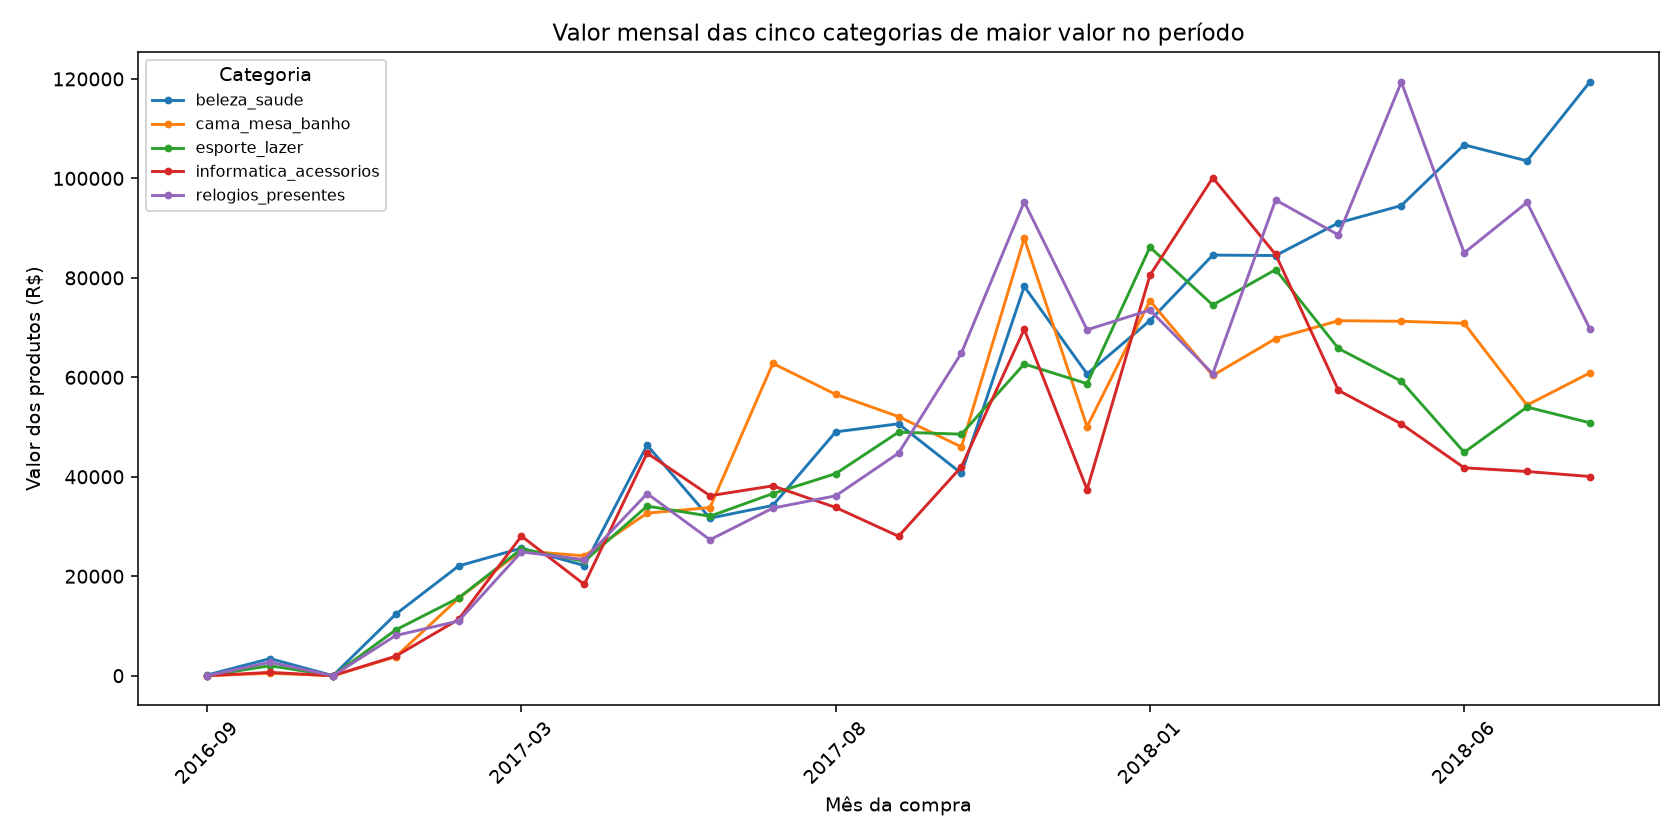

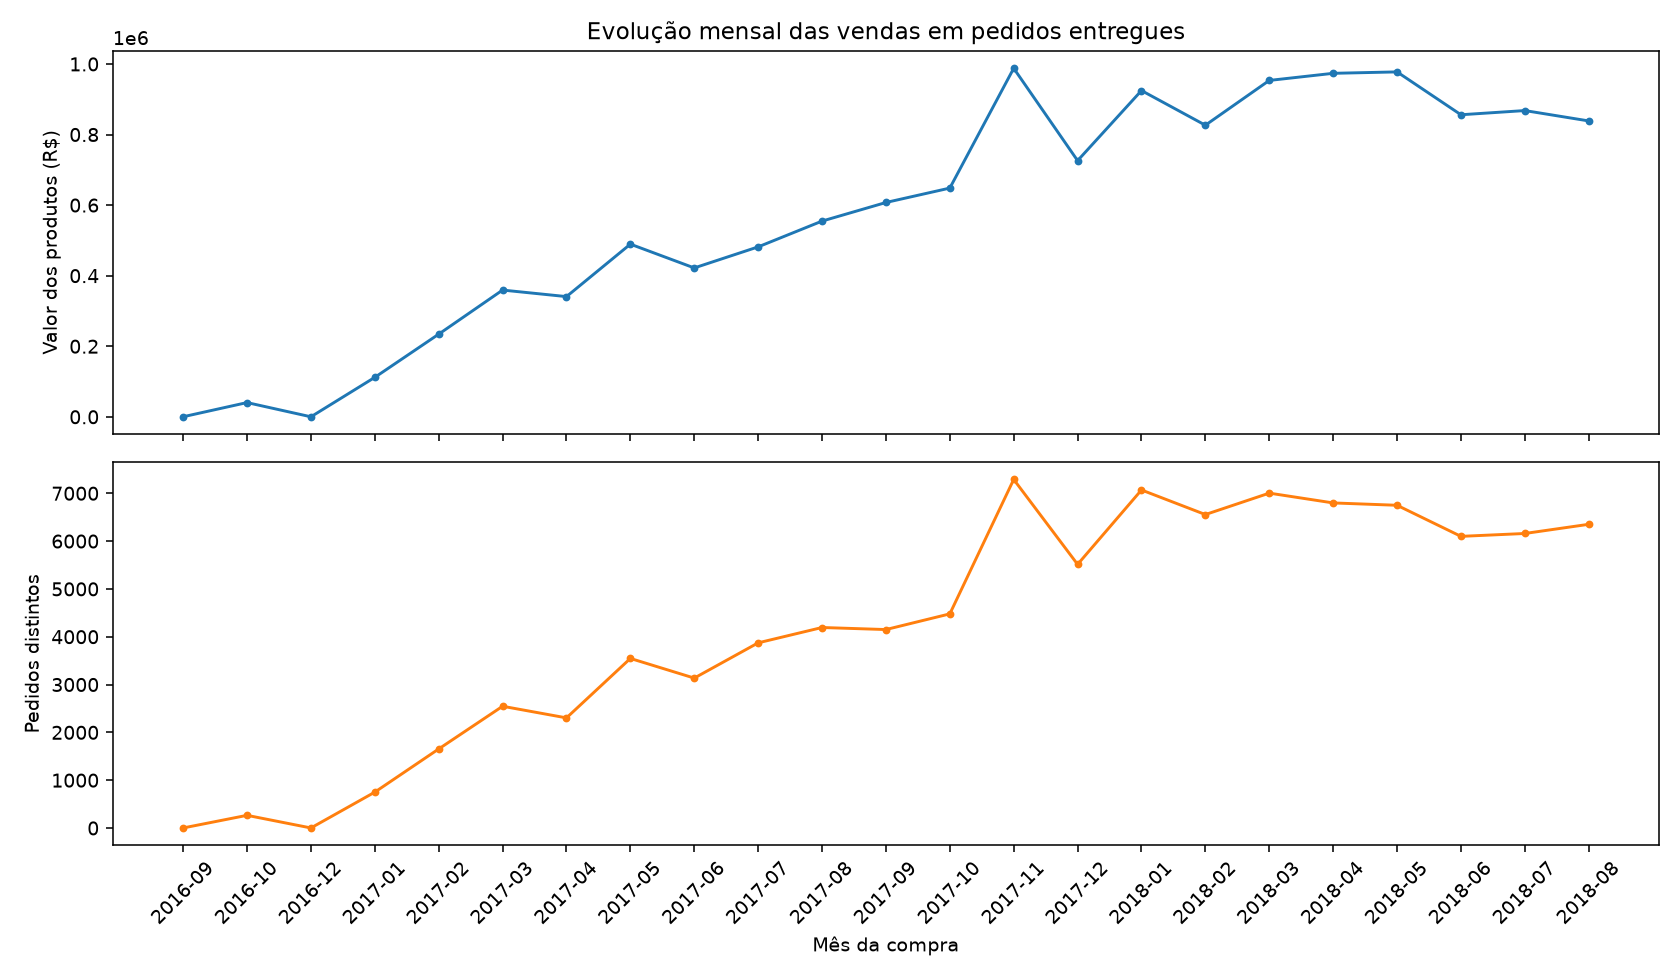

In [19]:
display(Image(filename=str(CONFIG['gold']/'graficos'/'categorias_mes.png')))
display(Image(filename=str(CONFIG['gold']/'graficos'/'evolucao_mensal.png')))

## Bloco 10 — Parametrizar o pipeline

Os caminhos, fontes, nomes de arquivos e filtros ficam no dicionário do início.
Testamos outro período sem alterar as funções, com início inclusivo e fim exclusivo.
O teste fica em outra pasta; depois restauramos a configuração da carga principal.

In [20]:
raiz_parametro = CONFIG['testes']/f'parametro_{uuid4().hex[:8]}'
try:
    configurar_pastas(raiz_parametro)
    CONFIG.update(fontes=fontes_teste,inicio='2018-01-01',fim='2018-04-01')
    gold_parametro = pipeline()
    esperado = golds['mensal'].query("mes >= '2018-01' and mes < '2018-04'").reset_index(drop=True)
    pd.testing.assert_frame_equal(gold_parametro['mensal'],esperado)
    registro = pd.read_csv(CONFIG['historico']).iloc[-1]
    assert json.loads(registro.parametros)['inicio']=='2018-01-01'
    display(gold_parametro['mensal'])
finally:
    CONFIG.clear()
    CONFIG.update(base_config)

C:\Users\foxyg\AppData\Local\Temp\ipykernel_6468\3925793808.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  tempo['dia_semana'] = tempo.data.dt.dayofweek  # segunda=0; domingo=6


,mes,valor_centavos,pedidos_distintos,valor_produtos
0,2018-01,92464500,7069,924645.00
1,2018-02,82643713,6555,826437.13
2,2018-03,95335625,7003,953356.25


### Bloco 10 — Perguntas de verificação

**P1. Quantos pontos mudaram?** Nenhuma função foi alterada. Mudamos a configuração
de início, fim e destino do teste. As fontes locais congelam o conteúdo usado na validação.

**P2. O que o log informa quando falha?** Etapa, parâmetros, horário e causa com traceback.
O teste de load sem Silver gerou um ERROR real, com mensagem sobre a entrada ausente.

**P3. Que parâmetro pode produzir uma Gold errada sem erro?** Status ou período incorreto
pode gerar resultado tecnicamente válido, mas fora da pergunta do grupo.

**P4. Por que guardar parâmetros no histórico?** Para distinguir escopos e reproduzir
resultados. Horário e quantidade de linhas sozinhos não explicam uma execução.

## Bloco 11 — Documentação e reprodutibilidade

O README explica ambiente, fontes, camadas, decisões e ordem de execução.
O requirements.txt registra as versões efetivamente usadas nesta execução.

### Perguntas de verificação

**P1. O pipeline de outro grupo rodou?** Pendente. A troca ainda não ocorreu.

**P2. A Gold entre computadores foi igual?** Pendente. Depende da revisão cruzada.

**P3. O que só funciona nesta máquina?** O código usa caminhos relativos e não depende
de um caminho pessoal. A execução local foi conferida, mas a confirmação em outro
computador continua pendente. São necessários Python, dependências, kernel correto
e acesso à internet para os downloads iniciais.

**P4. O que aproveitar do README do outro grupo?** Pendente. Registraremos somente
sugestões obtidas após a leitura e execução reais.

### Situação da entrega

As evidências ficam nas saídas, no log e no histórico. Falta a revisão por outro grupo, que será registrada quando ocorrer.
A composição de cinco integrantes já foi autorizada pelo professor.

In [21]:
import importlib.metadata as metadata
dependencias = ['pandas','pyarrow','matplotlib','requests','ipykernel','nbformat','nbclient']
Path('requirements.txt').write_text(''.join(f'{nome}=={metadata.version(nome)}\n' for nome in dependencias),encoding='utf-8')
for caminho in [CONFIG['bronze'],CONFIG['silver'],CONFIG['gold'],Path('README.md'),Path('requirements.txt')]:
    assert caminho.exists(),f'Falta na entrega: {caminho}'

